# **DSK807: Applied Machine Learning**
## Exercise Session 04: Decision Trees and Ensemble Methods

The main focus is on:

- Decision Trees
- Random Forests
- Voting ensembles
- comparison with previously studied models such as Logistic Regression and SVC
- feature preparation
- model evaluation
- hyperparameter tuning with `GridSearchCV`
- interpretation and discussion

### **Important**

There is rarely one universally "best" model. Your task is not only to obtain a high score, but also to **understand why models behave differently**.

Keep the **test set untouched during model selection and hyperparameter tuning**. Use it only for final evaluation.

## **Setup**

Run the following cell to import the libraries used throughout the exercises.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, VotingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

RANDOM_STATE = 42

# **Exercise 1: Employee Attrition**

Employee attrition is a binary classification problem: can we predict whether an employee will leave a company?

In this exercise you will compare Logistic Regression, Support Vector Machine, and Decision Tree. The main focus is understanding **Decision Trees**, their hyperparameters, feature importance, and their relationship to preprocessing.

## 1.1 Load and inspect the data

Load the IBM HR Analytics Employee Attrition dataset from the local file `HR-Employee-Attrition.csv` (available in itslearning).

In [2]:
path = "HR-Employee-Attrition.csv"

df = pd.read_csv(path)

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [3]:
len(df)

1470

In [4]:
df.columns[df.isna().all()]

Index([], dtype='str')

In [5]:
num_cols = df.select_dtypes(include="number").columns
cat_cols = df.select_dtypes(exclude="number").columns

n_df = df.copy()

print(num_cols)
print(cat_cols)

Index(['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome',
       'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike',
       'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours',
       'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear',
       'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole',
       'YearsSinceLastPromotion', 'YearsWithCurrManager'],
      dtype='str')
Index(['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime'],
      dtype='str')


In [6]:
# data checking, identical

df["PerformanceRating"].value_counts()

PerformanceRating
3    1244
4     226
Name: count, dtype: int64

In [7]:
# data checking, cat


waiting_list = ['Attrition', 'BusinessTravel', 'Department', 'EducationField', 'Gender',
       'JobRole', 'MaritalStatus', 'Over18', 'OverTime']

for col in waiting_list:
    print(df[col].value_counts().to_dict())

{'No': 1233, 'Yes': 237}
{'Travel_Rarely': 1043, 'Travel_Frequently': 277, 'Non-Travel': 150}
{'Research & Development': 961, 'Sales': 446, 'Human Resources': 63}
{'Life Sciences': 606, 'Medical': 464, 'Marketing': 159, 'Technical Degree': 132, 'Other': 82, 'Human Resources': 27}
{'Male': 882, 'Female': 588}
{'Sales Executive': 326, 'Research Scientist': 292, 'Laboratory Technician': 259, 'Manufacturing Director': 145, 'Healthcare Representative': 131, 'Manager': 102, 'Sales Representative': 83, 'Research Director': 80, 'Human Resources': 52}
{'Married': 673, 'Single': 470, 'Divorced': 327}
{'Y': 1470}
{'No': 1054, 'Yes': 416}


In [8]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [9]:
n_df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

---

Explore the dataset before building any model.

**Tasks**

1. How many observations and features are available?
2. What is the target variable?
3. Check the data types.
4. Check for missing values.
5. Check the class distribution of the target.
6. Identify columns that appear to contain no useful predictive information, such as IDs or constant columns.
7. Decide which columns you want to remove.

Do not start modelling until you understand what the rows and columns represent.

### Discussion

Before continuing, discuss with your group:

- Is this dataset balanced?
- Would accuracy alone be sufficient for evaluating the models?
- Which class would you consider the positive class?
- Are there columns that should be removed even though they contain no missing values?

---

## 1.2 Prepare the features

Separate the target `Attrition` from the input features.

Convert the target into a numerical binary representation.

Then identify:

- numerical features
- categorical features

Create a train/test split using **80% training and 20% testing**.

In [10]:
y = n_df["Attrition"]
X = n_df.drop(columns=["Attrition", "Over18", "EmployeeNumber", "EmployeeCount", "StandardHours"])


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

## 1.3 Preprocessing

Logistic Regression and SVC are sensitive to feature scale. Categorical variables must also be converted into numerical features.

Create an appropriate preprocessing strategy using:

- `StandardScaler`
- `OneHotEncoder`
- `ColumnTransformer`

Think about what should happen to numerical and categorical features.

> **Question:** Does a Decision Tree actually require feature scaling? Keep this question in mind—we will test it later.

In [11]:
# adjust by sklearn

# # ! build a processor -> 
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

one_hot_cols = ["Department", "EducationField", "JobRole", "MaritalStatus"]
ordinal_cols = ["BusinessTravel", "Gender", "OverTime"]

encode = make_column_transformer(
    (OneHotEncoder(drop="first", sparse_output=False), one_hot_cols),
    (OrdinalEncoder(categories=[
        ["Non-Travel", "Travel_Rarely", "Travel_Frequently"],   # BusinessTravel
        ["Female", "Male"],                                     # Gender
        ["No", "Yes"],                                          # OverTime
    ]), ordinal_cols),
    remainder="passthrough",
    verbose_feature_names_out=False,
).set_output(transform="pandas")

preprocess = make_pipeline(encode, StandardScaler()).set_output(transform="pandas")

X_train_t = preprocess.fit_transform(X_train)
X_test_t = preprocess.transform(X_test)

y_train = y_train.map({"No": 0, "Yes": 1})
y_test = y_test.map({"No": 0, "Yes": 1})


In [12]:
## adjust it, by pandas


# waiting_list_to_num = ['Attrition', 'Gender', 'OverTime']
# waiting_list_to_one_hot = ['Department', 'EducationField','JobRole', 'MaritalStatus']

# for col in waiting_list_to_num:
#     n_df[f"t_{col}"] = df[col].astype("category").cat.codes


# # have to pick and manual d
# n_df["t_BusinessTravel"] = df["BusinessTravel"].map(
#     {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
# )

# n_df = pd.get_dummies(
#     n_df,
#     columns=waiting_list_to_one_hot,
#     prefix=[f"t_oh_{c}" for c in waiting_list_to_one_hot],
#     drop_first=True,
#     dtype=int,
# )


## drop
# n_df = n_df.drop(columns=waiting_list_to_num)

# # EmployeeCount,Over18,StandardHours identical for all
# n_df = n_df.drop(columns=["Over18", "EmployeeNumber", "EmployeeCount","StandardHours"])

# # have to drop "BusinessTravel"
# n_df = n_df.drop(columns=["BusinessTravel"])

# pd.crosstab(df["BusinessTravel"], n_df["t_BusinessTravel"])

## 1.4 Establish baseline models

Train the following three classifiers:

- Logistic Regression
- SVC
- Decision Tree

Start with mostly default hyperparameters.

Evaluate each model on the test set using:

- Accuracy
- Precision
- Recall
- F1-score

Store the results in a table so that the models can be compared easily.

In [48]:
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import average_precision_score


param_grids = {
    "LogisticRegression": {
        "C": [0.05, 0.1, 0.2, 0.5, 1],         # 0.1 在上次範圍邊緣，往上延伸
        "l1_ratio": [0.7, 0.85, 1],            # 1 已經是最大值，改試它附近
    },
    "SVC": {
        "kernel": ["rbf"],                     # linear 已經輸給 rbf，拿掉
        "C": [0.7, 1, 1.5],                    # 上次挑 1，在中間，縮小範圍
        "gamma": [0.002, 0.003, 0.005],        # 上次挑 0.003，在中間
    },
    "DecisionTree": {
        "max_depth": [3, 4, 5],                # 上次挑 4
        "min_samples_leaf": [15, 20, 30],      # 上次挑 20
    },
    "HistGradientBoostingClassifier": {        # 已收斂，維持不變
        "learning_rate": [0.05, 0.1],
        "max_iter": [100, 200, 300],
        "max_depth": [2],
        "l2_regularization": [10.0],
        "min_samples_leaf": [100],
    },
    "RandomForest": {
        "max_depth": [7, 10, 15],              # 上次挑 10
        "min_samples_leaf": [3, 5, 10],        # 上次挑 5
        "max_features": ["sqrt"],              # 上次挑 sqrt，0.3 拿掉
    },
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


models = {
    "LogisticRegression": LogisticRegression(penalty="elasticnet", solver="saga", class_weight="balanced", max_iter=5000, random_state=RANDOM_STATE),
    "SVC": SVC(kernel="rbf", class_weight="balanced",probability=True, random_state=RANDOM_STATE),# THIS IS SO ANNORNING
    "DecisionTree": DecisionTreeClassifier(class_weight="balanced",random_state=RANDOM_STATE),
    "HistGradientBoostingClassifier": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(class_weight="balanced",max_features="sqrt",random_state=RANDOM_STATE),
}

results = []
best_models = {}
for name, model in models.items():
    grid = GridSearchCV(
        model,
        param_grids[name],
        scoring="average_precision",   # 用 PR-AUC 挑參數
        cv=cv,
        n_jobs=-1,                     # 用所有 CPU 核心平行計算
    )
    grid.fit(X_train_t, y_train)

    best = grid.best_estimator_
    best_models[name] = best

    y_pred = best.predict(X_test_t)
    y_prob = best.predict_proba(X_test_t)[:, 1]

    results.append({
        "model": name,
        "cv_pr_auc": grid.best_score_,
        "accuracy": accuracy_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_prob),
        "pr_auc": average_precision_score(y_test, y_prob),
        "best_params": grid.best_params_,
    })

results_df = pd.DataFrame(results).set_index("model").round(3)
print(results_df)

/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/fangsiyu/dev-env/lib/python3.13/s

                                cv_pr_auc  accuracy  recall     f1  roc_auc  \
model                                                                         
LogisticRegression                  0.644     0.782   0.681  0.500    0.804   
SVC                                 0.657     0.799   0.681  0.520    0.804   
DecisionTree                        0.371     0.701   0.511  0.353    0.696   
HistGradientBoostingClassifier      0.631     0.789   0.681  0.508    0.798   
RandomForest                        0.559     0.827   0.596  0.523    0.766   

                                pr_auc  \
model                                    
LogisticRegression               0.589   
SVC                              0.553   
DecisionTree                     0.311   
HistGradientBoostingClassifier   0.549   
RandomForest                     0.404   

                                                                      best_params  
model                                                              

In [37]:
for name, params in results_df["best_params"].items():
    print(name, params)
# results_df["best_params"]

LogisticRegression {'C': 0.1, 'l1_ratio': 1}
SVC {'C': 1, 'gamma': 0.003, 'kernel': 'rbf'}
DecisionTree {'max_depth': 4, 'min_samples_leaf': 15}
HistGradientBoostingClassifier {'l2_regularization': 10.0, 'learning_rate': 0.05, 'max_depth': 2, 'max_iter': 200, 'min_samples_leaf': 100}
RandomForest {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 5}


## Decide the threshold

In [42]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

target_recall = 0.7
results = {}

for name in ["LogisticRegression", "SVC", "HistGradientBoostingClassifier"]:
    m = best_models[name]
    method = "predict_proba" if hasattr(m, "predict_proba") else "decision_function"

    # 訓練集上每筆資料由「沒看過它」的模型打分數
    oof = cross_val_predict(m, X_train_t, y_train, cv=cv, method=method)
    if method == "predict_proba":
        oof = oof[:, 1]

    # 找出 recall 仍達到目標的最高門檻
    prec, rec, thr = precision_recall_curve(y_train, oof)
    idx = np.where(rec[:-1] >= target_recall)[0][-1]
    t = thr[idx]

    # 套用到測試集
    if method == "predict_proba":
        test_score = m.predict_proba(X_test_t)[:, 1]
    else:
        test_score = m.decision_function(X_test_t)
    y_pred = (test_score >= t).astype(int)

    results[name] = {
        "threshold": t,
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        "y_pred": y_pred,
    }

metrics = ["threshold", "precision", "recall", "f1", "accuracy"]
print(pd.DataFrame({n: [r[k] for k in metrics] for n, r in results.items()}, index=metrics).T.round(3))

/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/fangsiyu/dev-env/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/Users/fangsiyu/dev-env/lib/python3.13/s

                                threshold  precision  recall     f1  accuracy
LogisticRegression                  0.546      0.437   0.660  0.525     0.810
SVC                                 0.221      0.431   0.596  0.500     0.810
HistGradientBoostingClassifier      0.483      0.386   0.681  0.492     0.776


## 1.5 Confusion matrices

Plot the confusion matrix for each model.

Study the types of errors made by the models.

### Discuss

1. Which model has the highest accuracy?
2. Which has the highest recall?
3. Are these necessarily the same model?
4. In an employee attrition application, which error might be more important: a false positive or a false negative?

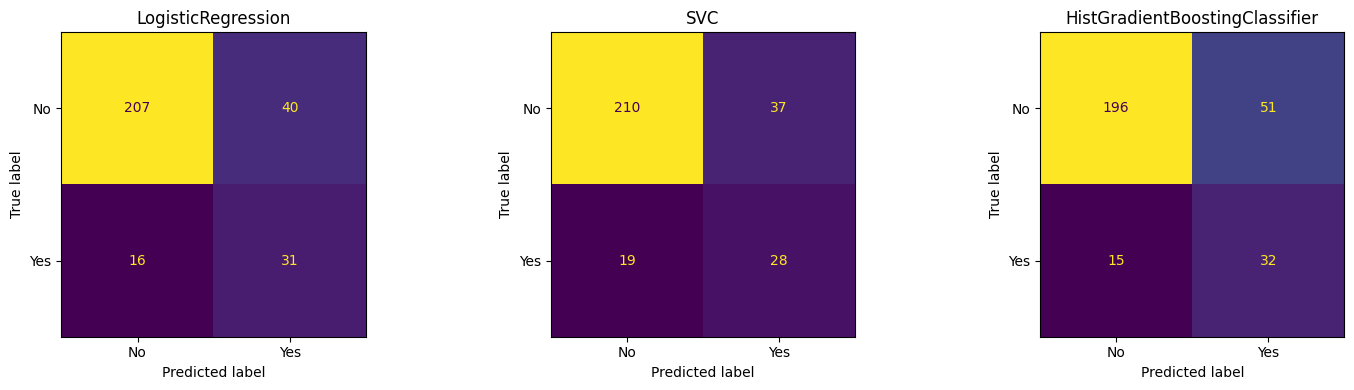

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, r) in zip(axes, results.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, r["y_pred"], ax=ax, colorbar=False, display_labels=["No", "Yes"]
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

## 1.6 Investigate the Decision Tree

Train Decision Trees with different values of `max_depth`, for example:

`1, 2, 3, 5, 10, None`

For every tree, calculate:

- training accuracy
- test accuracy

Create a table or plot showing how performance changes with tree depth.

           train_accuracy  test_accuracy
max_depth                               
1                   0.840          0.782
2                   0.713          0.735
3                   0.713          0.728
5                   0.852          0.769
6                   0.846          0.759
7                   0.862          0.762
8                   0.885          0.728
9                   0.942          0.762
10                  0.974          0.748
None                1.000          0.752


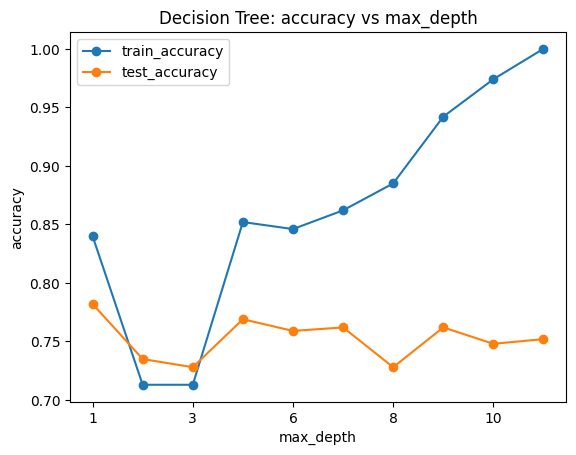

In [46]:
depths = [1, 2, 3, 5,6,7,8,9, 10, None]
results = {}

for d in depths:
    tree = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE)
    tree.fit(X_train_t, y_train)
    results[str(d)] = {
        "train_accuracy": accuracy_score(y_train, tree.predict(X_train_t)),
        "test_accuracy": accuracy_score(y_test, tree.predict(X_test_t)),
    }

depth_df = pd.DataFrame(results).T.round(3)
depth_df.index.name = "max_depth"
print(depth_df)

depth_df.plot(marker="o")
plt.xlabel("max_depth")
plt.ylabel("accuracy")
plt.title("Decision Tree: accuracy vs max_depth")
plt.show()

### Discussion: Overfitting

Use your results to answer:

- What happens to training performance as the tree becomes deeper?
- What happens to test performance?
- Can you identify evidence of overfitting?
- Why can an unrestricted Decision Tree become problematic?

## 1.7 Visualize a Decision Tree

Train a relatively small Decision Tree, for example with `max_depth=3`, and visualize it using `plot_tree`.

Try to interpret at least one path from the root node to a leaf.

> **Hint:** If you use one-hot encoding, you may need to retrieve the transformed feature names from your preprocessing pipeline.

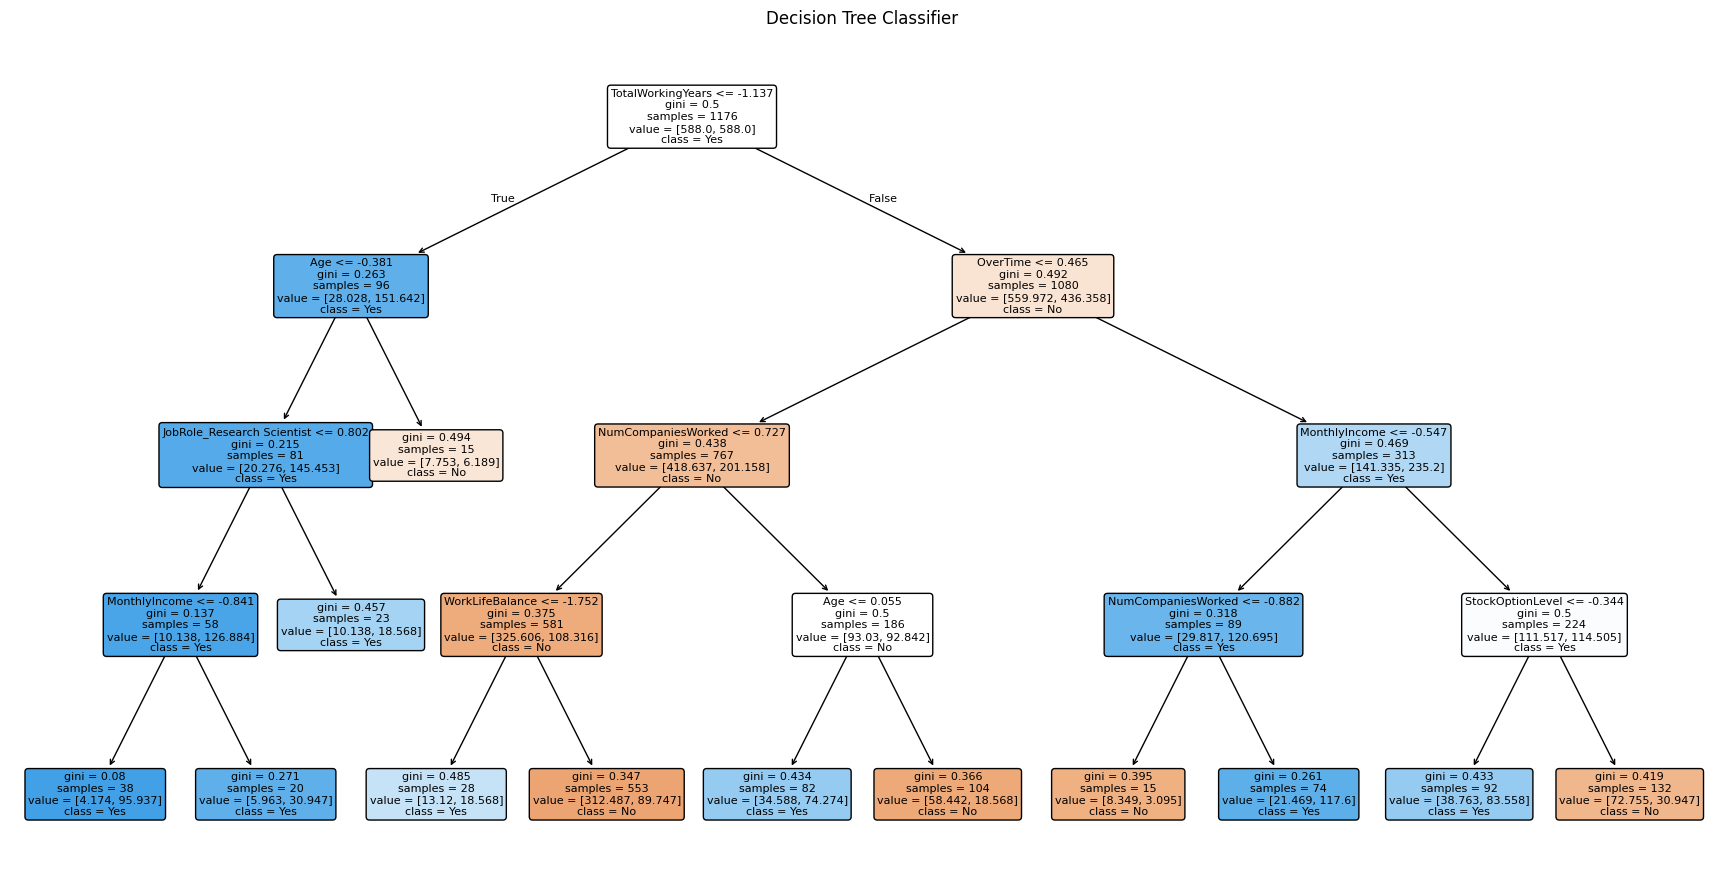

In [54]:
from sklearn.tree import plot_tree

plt.figure(figsize=(22, 11))

plot_tree(
    best_models["DecisionTree"],
    feature_names=X_train_t.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier")
plt.show()

## 1.8 Feature importance

Extract the feature importances from the Decision Tree.

Display the **10 most important features** using a horizontal bar chart.

### Discuss

- Which features appear most important?
- Are the results plausible?
- Does high feature importance mean that the feature **causes** employee attrition?

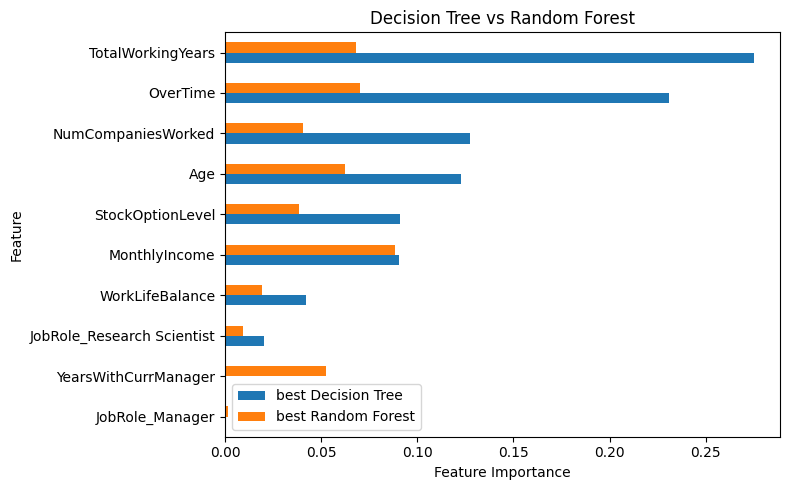

In [51]:
importance_reg = pd.DataFrame({
    "Feature": X_train_t.columns,
    "best Decision Tree": best_models["DecisionTree"].feature_importances_,
    "best Random Forest": best_models["RandomForest"].feature_importances_,
}).sort_values("best Decision Tree")

importance_reg.set_index("Feature").tail(10).plot(
    kind="barh",
    figsize=(8, 5)
)

plt.xlabel("Feature Importance")
plt.title("Decision Tree vs Random Forest")
plt.tight_layout()
plt.show()


---

# **Exercise 2: Adult Income Classification**

We now move to a more challenging classification problem.

The goal is to predict whether a person's annual income is above \$50,000 using census-related attributes.

This exercise introduces two ensemble approaches:

- **Random Forest**
- **Voting Classifier**

You will compare them with individual classifiers and use `GridSearchCV` for model selection.

## 2.1 Load the Adult dataset

Load the Adult Income dataset from the local file `adult.csv` (available in itslearning).

First inspect the dataset and its column names, then separate the input features from the target variable `income`.

In [ ]:
# Load the Adult Income dataset from a local CSV file
# df = pd.read_csv("adult.csv")

# Inspect the dataset
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [ ]:
df.columns

Index(['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department',
       'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount',
       'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate',
       'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction',
       'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked',
       'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating',
       'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel',
       'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance',
       'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion',
       'YearsWithCurrManager'],
      dtype='str')

In [ ]:
X = df.drop(columns=["income"])
y = df["income"]

X.head()

KeyError: "['income'] not found in axis"

## 2.2 Explore, clean, and prepare the target

Investigate the shape, target distribution, data types, missing values, and categorical/numerical variables.

Pay particular attention to how missing information is represented. Depending on the CSV version, missing values may appear as `NaN`, `?`, or strings containing extra spaces.

Then prepare the target variable `income` as a binary numerical variable:

- `<=50K` → `0`
- `>50K` → `1`

This will make the classification metrics and later model comparisons easier to work with.

Prepare the dataset for modelling and document any cleaning decisions you make.


In [ ]:
# Your code here

## 2.3 Train/test split and preprocessing

Create a stratified **80/20 train/test split**.

Construct an appropriate preprocessing pipeline.

Remember:

- categorical variables need encoding;
- Logistic Regression and SVC benefit from scaling;
- tree-based models do not require scaling.

You may use a common preprocessing pipeline for convenience, or create separate preprocessing pipelines if you want to investigate these differences explicitly.

In [ ]:
# Your code here

## 2.4 Build individual classifiers

Train:

1. Logistic Regression
2. SVC
3. Decision Tree

Evaluate them using appropriate classification metrics.

Create a comparison table.

### Question

Which model would you use as your baseline for the ensemble experiments, and why?

In [ ]:
# Your code here

## 2.5 Random Forest

Train a `RandomForestClassifier`.

Start with reasonable default settings and compare its performance with the single Decision Tree.

Also compare:

- training performance
- test performance

### Discuss

- Does the Random Forest generalize better than the Decision Tree?
- Why can combining many trees reduce the instability of a single Decision Tree?

In [ ]:
# Your code here

## 2.6 Feature importance with Random Forest

Extract the feature importances from your Random Forest.

Plot the **5 most important features**.

Compare them with what you observed for the Decision Tree.

### Discuss

Do the two models identify the same important features? Why might their rankings differ?

In [ ]:
# Your code here

## 2.7 Voting Classifier

Create a `VotingClassifier` that combines:

- Logistic Regression
- SVC
- Decision Tree

Start with **hard voting**.

Compare the Voting Classifier with each individual model.

### Questions

1. Did voting improve the result?
2. Does an ensemble necessarily outperform every individual model?
3. Why can diversity among the individual models be useful?

In [ ]:
# Your code here

## 2.8 Optional: Soft Voting

Investigate **soft voting**.

Before implementing it, answer:

> What additional information does a soft-voting classifier need from each model?

Check the `SVC` documentation and determine which setting is required.

Then build a soft-voting ensemble and compare it with hard voting.

In [ ]:
# Optional: your code here

## 2.9 Hyperparameter tuning with GridSearchCV

Now optimize the Random Forest.

Investigate a grid containing parameters such as:

- `n_estimators`
- `max_depth`
- `min_samples_split`
- `max_features`

You do **not** need to use an enormous grid. A well-designed small grid is sufficient.

Use cross-validation and choose an appropriate scoring metric.

In [ ]:
# Example starting point – modify if appropriate

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5, 10],
    "max_features": ["sqrt", "log2"]
}

# Continue here

## 2.10 Final evaluation

After `GridSearchCV` has selected the best hyperparameters:

1. report the best parameters;
2. report the best cross-validation score;
3. evaluate the selected model **once** on the test set;
4. compare it with the untuned Random Forest.

### Discussion

- Did tuning improve test performance?
- Is the combination with the highest cross-validation score guaranteed to be the best on unseen data?
- Why should the test set not be used to choose hyperparameters?

In [ ]:
# Your code here

---
# Final Reflection

Before finishing the exercise session, compare what you observed across the two classification datasets.

Discuss with your group:

1. When did Decision Trees perform well?
2. What was the main weakness of a single Decision Tree?
3. How did Random Forest address this weakness?
4. When did Voting help?
5. Why does feature scaling matter for Logistic Regression and SVC but not for Decision Trees?
6. What role did cross-validation play in hyperparameter tuning?
7. Why must the test set remain separate from model selection?
8. What trade-off did you observe between model complexity, interpretability, and predictive performance?

Be prepared to discuss your findings with the class.
